MECH 5005F | RFP-02 Mission Simulation

DJI Matrice 400 + Zenmuse L3 | LZ-01, Highway 37 parking lot

Place rfp02_config.py beside this notebook, then restart the kernel and run all cells. Dependencies are NumPy, pandas and Matplotlib. The figure and results files export to mission_outputs/. Set export_video to True for the PowerPoint MP4 (requires FFmpeg on PATH).

1. Inputs and mission sequence

Use the same RFP polygon, concept-map digitization, DJI specifications, route solver and timing assumptions as the r03 site optimizer. The model uses a flat reference surface and the approved planning choice of LZ-01. Each sortie climbs, transits, acquires LiDAR and RGB on the parallel strips, returns and lands. Ground time includes survey control, setup and packdown, battery changes and data checks, and a general delay allowance. The calendar places the reserve delay before packdown for display. Its timing may vary in the field.

Sources: RFP-02 Appendix A and Sec. 5, project outline Sec. 4, concept slide 11, [L3 specs](https://enterprise.dji.com/zenmuse-l3/specs), [L3 User Manual](https://dl.djicdn.com/downloads/Zenmuse_L3/20251104/Zenmuse_L3_User_Manual_v1.0_en.pdf) and [L3 Operational White Paper](https://rtk.mx/wp-content/uploads/2026/10/Zenmuse_L3_Operational_White_Paper_v1.0-1.pdf).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.path import Path as PlotPath
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from IPython.display import display

import rfp02_config as cfg

output_dir = Path("mission_outputs")
output_dir.mkdir(exist_ok=True)
export_video = True
show_plots = True

site_id = cfg.mission_site_id
ranking, plans = cfg.compare(cfg.line_spacing_m, cfg.airborne_endurance_min)
if site_id not in plans:
    raise ValueError(f"{site_id} has no schedule under the current shared inputs.")
plan = plans[site_id]
base = cfg.sites[site_id].xy
route = plan["route"]
field_days, total_min, schedule = plan["result"]
print(f"{cfg.site_label(site_id)} | bearing {plan['bearing']} degrees | {len(route)} strips")
print(f"Flight ceiling per sortie: {cfg.usable_flight_min:.2f} min, including the landing-reserve deduction.")

LZ-01 · Hwy 37 parking lot | bearing 120 degrees | 65 strips
Flight ceiling per sortie: 33.75 min, including the landing-reserve deduction.


2. Time-based trajectory

Each segment has a start and end time and a start and end position. The elapsed clock advances at the configured ground speeds on straight horizontal segments. A stationary turn delay is charged before each repositioning leg. The combined climb/descent budget is split equally and used to interpolate altitude. A survey segment starts triggering both RGB cameras immediately, then every configured photo interval until the segment ends. LiDAR records continuously during survey segments. The time origin is the start of field work. For multiple field days, the clock counts field time and omits overnight downtime.

In [2]:
segments, photo_events, sortie_rows = [], [], []

def add_segment(phase, start, end, duration_s, z0=0, z1=0, strip=None):
    t0 = segments[-1]["end_s"] if segments else 0.0
    segments.append(dict(day=day, sortie=sortie, phase=phase, start_s=t0, end_s=t0 + duration_s,
                         east_start_m=start[0], north_start_m=start[1], height_start_m=z0,
                         east_end_m=end[0], north_end_m=end[1], height_end_m=z1,
                         distance_m=np.linalg.norm(end - start), strip=strip,
                         lidar_on=phase == "Survey", rgb_enabled=phase == "Survey"))
    if phase == "Survey":
        for offset in np.arange(0, duration_s, cfg.rgb_photo_interval_s):
            position = start + offset / duration_s * (end - start)
            photo_events.append((day, sortie, strip, t0 + offset, *position, z0, 2))

def fly(phase, start, end, speed, strip=None):
    height = cfg.flight_height_above_base_m
    add_segment(phase, start, end, np.linalg.norm(end - start) / speed, height, height, strip)

for day, day_plan in enumerate(schedule, 1):
    sortie = 0
    add_segment("Setup and checks", base, base, 30 * cfg.setup_packdown_min)
    add_segment("Survey control", base, base, 60 * cfg.survey_control_min_per_day)
    for sortie, (first, stop, optimizer_min) in enumerate(day_plan, 1):
        takeoff = segments[-1]["end_s"]
        first_event = len(segments)
        height = cfg.flight_height_above_base_m
        add_segment("Climb", base, base, cfg.climb_descent_min * 30, 0, height)
        fly("Outbound transit", base, route[first, 0], cfg.transit_speed_mps)
        for i in range(first, stop):
            start, end = route[i]
            if i > first:
                previous = route[i - 1, 1]
                add_segment("Turn", previous, previous, 60 * cfg.turn_delay_min, height, height)
                fly("Reposition", previous, start, cfg.transit_speed_mps)
            fly("Survey", start, end, cfg.survey_speed_mps, i + 1)
        fly("Return transit", route[stop - 1, 1], base, cfg.transit_speed_mps)
        add_segment("Descent", base, base, cfg.climb_descent_min * 30, height, 0)
        landing = segments[-1]["end_s"]
        actual_min = (landing - takeoff) / 60
        assert np.isclose(optimizer_min, actual_min)
        assert actual_min <= cfg.usable_flight_min + 1e-9
        legs = segments[first_event:]
        sortie_rows.append((day, sortie, first + 1, stop, takeoff / 60, landing / 60, actual_min,
                            cfg.usable_flight_min - actual_min, sum(s["distance_m"] for s in legs) / 1000))
        add_segment("Turnaround and data QA", base, base, 60 * cfg.turnaround_min)
    sortie = 0
    add_segment("Delay allowance", base, base, 60 * cfg.delay_allowance_min_per_day)
    add_segment("Packdown", base, base, 30 * cfg.setup_packdown_min)

timeline = pd.DataFrame(segments)
photos = pd.DataFrame(photo_events, columns=["day", "sortie", "strip", "time_s", "east_m", "north_m",
                                             "height_m", "images"])
sorties = pd.DataFrame(sortie_rows, columns=["Day", "Sortie", "First strip", "Last strip",
                                            "Takeoff min", "Landing min", "Airborne min", "Margin min",
                                            "Horizontal km"])
assert site_id == cfg.parking_id and cfg.access_minutes(cfg.sites[site_id]) == 0
assert np.isclose(timeline.end_s.iloc[-1] / 60, total_min)
assert np.allclose(timeline.end_s.iloc[:-1], timeline.start_s.iloc[1:])
for axis in ("east", "north", "height"):
    assert np.allclose(timeline[f"{axis}_end_m"].iloc[:-1], timeline[f"{axis}_start_m"].iloc[1:])
acquisition = timeline.loc[timeline.lidar_on]
assert acquisition.strip.tolist() == list(range(1, len(route) + 1))
display(sorties.round(2))
sorties.to_csv(output_dir / "sortie_schedule.csv", index=False)
timeline.to_csv(output_dir / "mission_timeline.csv", index=False)
photos.to_csv(output_dir / "rgb_triggers.csv", index=False)

,Day,Sortie,First strip,Last strip,Takeoff min,Landing min,Airborne min,Margin min,Horizontal km
0,1,1,1,13,77.50,110.37,32.87,0.88,18.06
1,1,2,14,23,117.37,148.03,30.66,3.09,16.70
2,1,3,24,33,155.03,185.83,30.81,2.94,16.71
3,1,4,34,39,192.83,213.04,20.21,13.54,10.53
4,1,5,40,45,220.04,240.50,20.46,13.29,10.68
5,1,6,46,55,247.50,279.94,32.44,1.31,17.68
6,1,7,56,65,286.94,320.43,33.49,0.26,18.41


3. Geometric coverage and engineering checks

Evaluate nominal coverage on a regular grid inside the RFP polygon. The RGB model counts a conservative rectangular footprint per dual-camera trigger, using the cropped combined swath and the minimum along-track footprint evaluated at the minimum design surface distance. Along each strip, consecutive footprints overlap and form a continuous rectangle from the first to the last trigger, extended by half the along-track footprint at both ends. The LiDAR model counts continuous strips with the minimum design swath and square ends. The traced shore separates approximate land and water cells. RGB is screened over the whole polygon to include the visible shoreline. The background and grid serve as proxies for a terrain and shoreline model.

Pulse emission divided by single-pass swath area per second gives a mean emitted density, with the maximum design surface distance giving the widest swath. Ground-return density and geospatial accuracy require processed data and independent checkpoints. The 10-business-day delivery requirement applies after acquisition and depends on the separate processing plan.

In [3]:
step = cfg.coverage_grid_m
x, y = np.meshgrid(np.arange(cfg.corners[:, 0].min() + step / 2, cfg.corners[:, 0].max(), step),
                   np.arange(cfg.corners[:, 1].min() + step / 2, cfg.corners[:, 1].max(), step))
grid = np.column_stack((x.ravel(), y.ravel()))
inside = PlotPath(cfg.corners).contains_points(grid)
points = grid[inside]
water = PlotPath(cfg.lake_xy).contains_points(points) & ~PlotPath(cfg.island_xy).contains_points(points)
lidar_hits = np.zeros(len(points), dtype=int)
rgb_hits = np.zeros(len(points), dtype=int)
assert cfg.survey_speed_mps * cfg.rgb_photo_interval_s < cfg.rgb_min_along_m
for strip, (start, end) in enumerate(route, 1):
    length = np.linalg.norm(end - start)
    unit = (end - start) / length
    displacement = points - start
    along = displacement[:, 0] * unit[0] + displacement[:, 1] * unit[1]
    cross = np.abs(displacement[:, 0] * unit[1] - displacement[:, 1] * unit[0])
    lidar_hits += (along >= 0) & (along <= length) & (cross <= cfg.lidar_width_m / 2)
    exposures = photos.loc[photos.strip == strip]
    last_photo = exposures.iloc[-1][["east_m", "north_m"]].to_numpy(dtype=float)
    rgb_end = np.dot(last_photo - start, unit)
    half_frame = cfg.rgb_min_along_m / 2
    rgb_hits += (along >= -half_frame) & (along <= rgb_end + half_frame) & (cross <= cfg.rgb_combined_width_m / 2)

coverage = pd.DataFrame([
    ("Terrestrial LiDAR", (~water).sum(), ((lidar_hits > 0) & ~water).sum()),
    ("Whole-area RGB (includes shoreline)", len(points), (rgb_hits > 0).sum()),
], columns=["Screen", "Cells tested", "Cells covered"])
coverage["Covered %"] = 100 * coverage["Cells covered"] / coverage["Cells tested"]
coverage["Uncovered cells"] = coverage["Cells tested"] - coverage["Cells covered"]
display(coverage.round(3))

survey_km = acquisition.distance_m.sum() / 1000
area_spacing_km = cfg.area / cfg.line_spacing_m / 1000
airborne_min = sorties["Airborne min"].sum()
nominal_pulses = cfg.lidar_pulse_rate_hz / (cfg.survey_speed_mps *
    2 * cfg.height_max_m * np.tan(np.radians(cfg.lidar_half_fov_deg)))
summary = pd.DataFrame([
    ("Survey polygon", cfg.area / 1e6, "km²"),
    ("Independent area/spacing estimate", area_spacing_km, "km"),
    ("Modelled survey distance", survey_km, "km"),
    ("Total horizontal distance", sorties["Horizontal km"].sum(), "km"),
    ("Total airborne time", airborne_min, "min"),
    ("Total field time", total_min / 60, "h"),
    ("Field days", field_days, "days"),
    ("Sorties", len(sorties), "sorties"),
    ("Minimum margin beyond reserve", sorties["Margin min"].min(), "min"),
    ("Max. modelled slant distance", plan["reach"] / 1000, "km"),
    ("RGB shutter events", len(photos), "paired exposures"),
    ("RGB images", photos.images.sum(), "images"),
    ("Worst modelled RGB GSD", cfg.gsd_max_cm, "cm/pixel"),
    ("Mean emitted single-pass pulses", nominal_pulses, "pulses/m²"),
], columns=["Metric", "Value", "Unit"])
display(summary.round(2))
summary.to_csv(output_dir / "mission_summary.csv", index=False)
coverage.to_csv(output_dir / "coverage_summary.csv", index=False)

,Screen,Cells tested,Cells covered,Covered %,Uncovered cells
0,Terrestrial LiDAR,62248,62248,100.0,0
1,Whole-area RGB (includes shoreline),115170,115170,100.0,0


,Metric,Value,Unit
0,Survey polygon,2.88,km²
1,Independent area/spacing estimate,89.98,km
2,Modelled survey distance,95.59,km
3,Total horizontal distance,108.77,km
4,Total airborne time,200.93,min
5,Total field time,6.17,h
6,Field days,1.00,days
7,Sorties,7.00,sorties
8,Minimum margin beyond reserve,0.26,min
9,Max. modelled slant distance,2.36,km


4. Report and presentation figures

The route map shows the acquisition blocks by sortie. The coverage maps show geometric swath multiplicity. The timeline shows the complete field campaign and the altitude and payload phases of one representative sortie. The nominal schedule uses seven batteries through one day, assuming one fully charged TB100 per sortie and no field charging.

The short minimum reserve margin is measured above the 25% planning reserve. Wind or rerouting can consume that margin, and a revised endurance budget can change the sortie split. Terrain, canopy clearance, C2 performance, park-user separation and approvals remain operational checks. The delay allowance is budgeted ground time and does not represent a simulated refly.

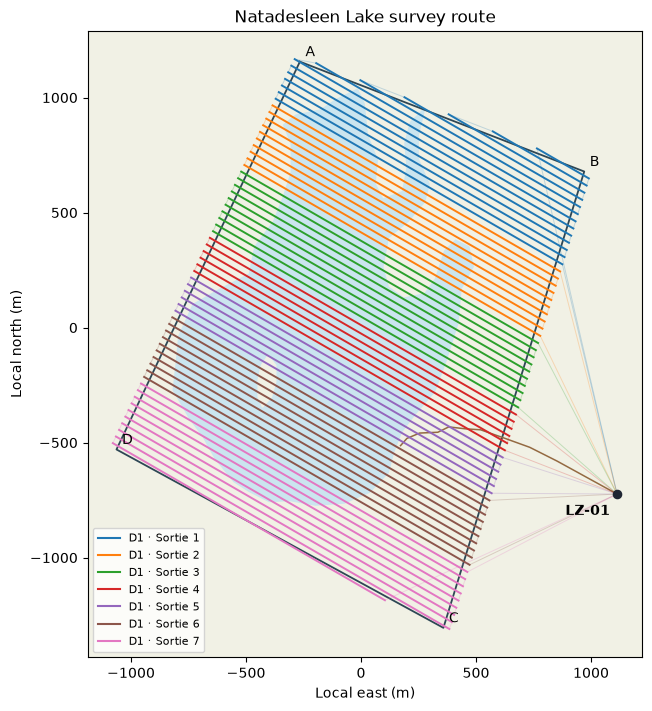

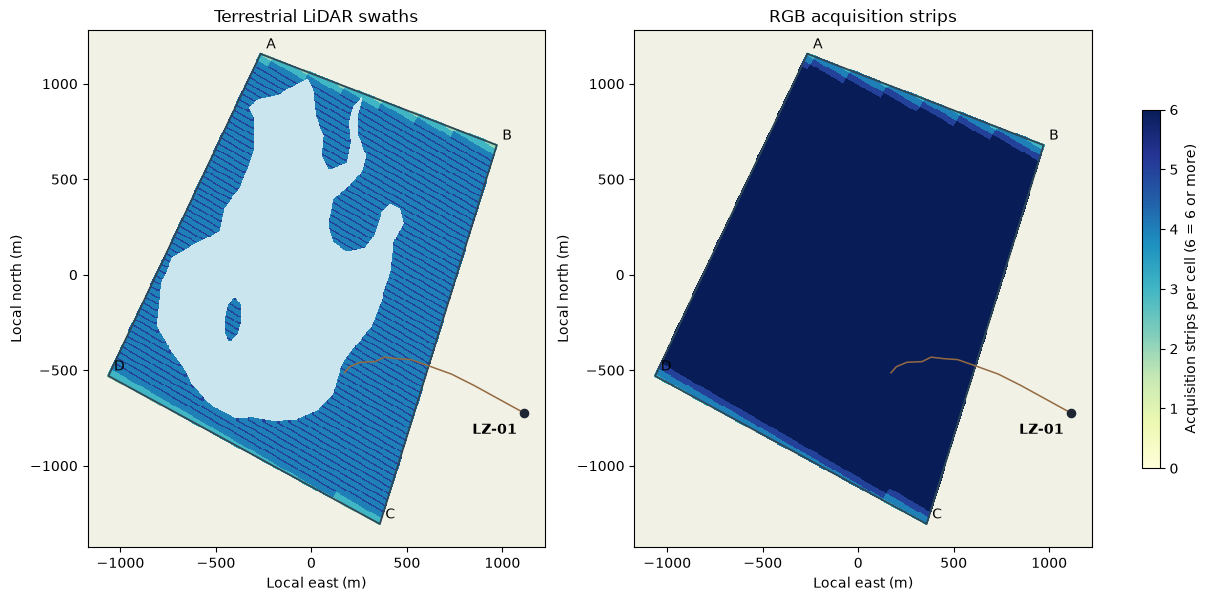

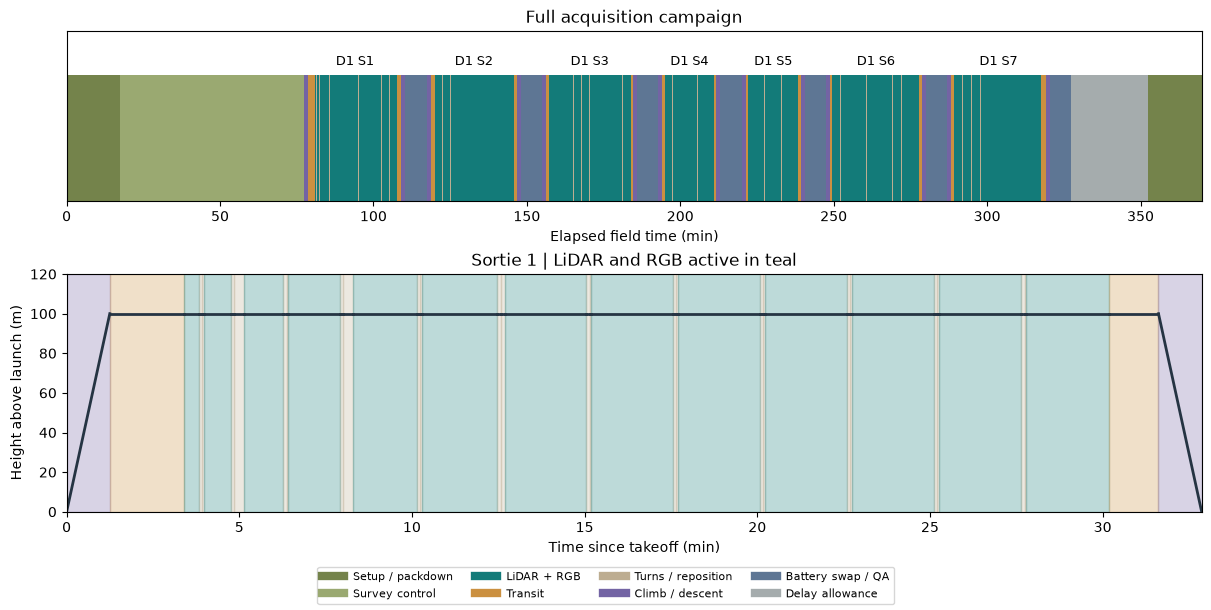

In [4]:
COLORS = {"Survey": "#137b79", "Outbound transit": "#cb9040", "Return transit": "#cb9040",
          "Reposition": "#bdad91", "Turn": "#bdad91", "Climb": "#7364a4", "Descent": "#7364a4",
          "Turnaround and data QA": "#5e7694", "Setup and checks": "#74834b",
          "Survey control": "#9aa971", "Delay allowance": "#a5acad", "Packdown": "#74834b"}

def map_base(ax):
    ax.set_facecolor("#f1f1e5")
    ax.fill(*cfg.lake_xy.T, color="#cbe5ef", zorder=0)
    ax.fill(*cfg.island_xy.T, color="#f1f1e5", zorder=0)
    ax.plot(*cfg.polygon.T, color="#2e4755", lw=1.3)
    ax.plot(*cfg.trail.T, color="#946a42", lw=1.1)
    ax.scatter(*base, c="#1f2633", s=35, zorder=7)
    ax.annotate(site_id, base, xytext=(-5, -15), textcoords="offset points", ha="right",
                fontweight="bold", zorder=7)
    ax.set(aspect="equal", xlabel="Local east (m)", ylabel="Local north (m)")
    for name, point in zip(cfg.corner_names, cfg.corners):
        ax.annotate(name, point, xytext=(4, 4), textcoords="offset points")

def save_figure(fig, name):
    fig.savefig(output_dir / name, dpi=200, facecolor="white")
    if show_plots:
        plt.show()
    plt.close(fig)

fig, ax = plt.subplots(figsize=(8.5, 7), layout="constrained")
map_base(ax)
for number, row in enumerate(sorties.itertuples(index=False, name=None)):
    day_id, sortie_id = row[:2]
    color = plt.cm.tab10(number % 10)
    legs = timeline[(timeline.day == day_id) & (timeline.sortie == sortie_id)]
    for leg in legs.itertuples():
        active = leg.lidar_on
        ax.plot([leg.east_start_m, leg.east_end_m], [leg.north_start_m, leg.north_end_m],
                color=color, alpha=1 if active else 0.24, lw=1.4 if active else 0.7)
    ax.plot([], [], color=color, label=f"D{day_id} · Sortie {sortie_id}")
ax.set_title("Natadesleen Lake survey route")
ax.legend(loc="lower left", fontsize=8)
save_figure(fig, "mission_route.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 6), layout="constrained")
for ax, hits, eligible, title in zip(axes, (lidar_hits, rgb_hits),
                                    (~water, np.ones(len(points), dtype=bool)),
                                    ("Terrestrial LiDAR swaths", "RGB acquisition strips")):
    map_base(ax)
    plotted = ax.scatter(*points[eligible].T, c=np.minimum(hits[eligible], 6), s=4, marker="s",
                         cmap="YlGnBu", vmin=0, vmax=6, linewidths=0, rasterized=True)
    gaps = eligible & (hits == 0)
    if gaps.any():
        ax.scatter(*points[gaps].T, s=10, c="#e04444", zorder=6, label="Geometric gap")
        ax.legend()
    ax.set_title(title)
fig.colorbar(plotted, ax=axes, label="Acquisition strips per cell (6 = 6 or more)", shrink=0.65)
save_figure(fig, "mission_coverage.png")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 6), layout="constrained",
                                  gridspec_kw={"height_ratios": [1, 1.4]})
for leg in timeline.itertuples():
    t0 = leg.start_s / 60
    width = (leg.end_s - leg.start_s) / 60
    top.broken_barh([(t0, width)], (0, 1), facecolors=COLORS[leg.phase])
for row in sorties.itertuples(index=False, name=None):
    day_id, sortie_id, _, _, takeoff, landing, *_ = row
    top.text((takeoff + landing) / 2, 1.08, f"D{day_id} S{sortie_id}", ha="center", fontsize=9)
top.set(xlim=(0, total_min), ylim=(0, 1.35), yticks=[], xlabel="Elapsed field time (min)",
        title="Full acquisition campaign")
first = timeline[(timeline.day == 1) & (timeline.sortie == 1) &
                 (timeline.phase != "Turnaround and data QA")]
origin = first.start_s.iloc[0]
for leg in first.itertuples():
    times = (np.array([leg.start_s, leg.end_s]) - origin) / 60
    bottom.axvspan(*times, color=COLORS[leg.phase], alpha=0.28)
    bottom.plot(times, [leg.height_start_m, leg.height_end_m], color="#253443", lw=2)
bottom.set(xlim=(0, (first.end_s.iloc[-1] - origin) / 60), ylim=(0, 120),
           ylabel="Height above launch (m)", xlabel="Time since takeoff (min)",
           title="Sortie 1 | LiDAR and RGB active in teal")
legend_phases = ["Setup and checks", "Survey control", "Survey", "Outbound transit",
                 "Reposition", "Climb", "Turnaround and data QA", "Delay allowance"]
legend_labels = ["Setup / packdown", "Survey control", "LiDAR + RGB", "Transit",
                 "Turns / reposition", "Climb / descent", "Battery swap / QA", "Delay allowance"]
fig.legend([Line2D([], [], color=COLORS[p], lw=6) for p in legend_phases], legend_labels,
           ncol=4, fontsize=8, loc="outside lower center")
save_figure(fig, "mission_timeline.png")

5. Presentation playback

The MP4 shows sortie 1 from takeoff to landing, then the complete acquisition campaign including ground activities. Each segment is linearly time-compressed. The visible clock follows the simulation. The aircraft marker turns teal during LiDAR/RGB acquisition and the altitude indicator uses the simulated flat height. The completed survey strips accumulate in teal. Set export_video in the first code cell and rerun for a fresh MP4.

In [6]:
import sys
from pathlib import Path
import matplotlib as mpl

mpl.rcParams["animation.ffmpeg_path"] = str(
    Path(sys.prefix) / "Library" / "bin" / "ffmpeg.exe"
)

In [7]:
if export_video:
    fps = 12
    detail_times = np.linspace(first.start_s.iloc[0], first.end_s.iloc[-1], 12 * fps)
    campaign_times = np.linspace(0, timeline.end_s.iloc[-1], 22 * fps)
    playback = np.concatenate([detail_times, campaign_times])
    ends = timeline.end_s.to_numpy()
    survey_ends = acquisition.end_s.to_numpy()

    fig, ax = plt.subplots(figsize=(12.8, 7.2), dpi=100)
    fig.subplots_adjust(left=0.08, right=0.66, bottom=0.12, top=0.86)
    map_base(ax)
    for strip in route:
        ax.plot(*strip.T, color="#86999d", lw=0.8, alpha=0.4)
    drawn = [ax.plot(*strip.T, color=COLORS["Survey"], lw=1.4, visible=False)[0] for strip in route]
    active_line, = ax.plot([], [], color=COLORS["Survey"], lw=2.8, zorder=6)
    aircraft, = ax.plot([], [], "o", mec="white", mew=1.5, ms=9, zorder=8)
    fig.text(0.08, 0.93, "Natadesleen Lake | Mission simulation", fontsize=21, weight="bold")
    segment_title = fig.text(0.69, 0.76, "", fontsize=14, weight="bold")
    readout = fig.text(0.69, 0.68, "", fontsize=13, va="top", linespacing=1.6)
    fig.text(0.69, 0.22, "Teal indicates data acquisition\nand completed survey strips.", fontsize=11)

    def update(frame):
        t = playback[frame]
        leg = timeline.iloc[min(np.searchsorted(ends, t, side="right"), len(timeline) - 1)]
        duration = leg.end_s - leg.start_s
        fraction = np.clip((t - leg.start_s) / duration, 0, 1) if duration else 1
        p0 = leg[["east_start_m", "north_start_m", "height_start_m"]].to_numpy(dtype=float)
        p1 = leg[["east_end_m", "north_end_m", "height_end_m"]].to_numpy(dtype=float)
        x, y, z = p0 + fraction * (p1 - p0)
        aircraft.set_data([x], [y])
        aircraft.set_color(COLORS["Survey"] if leg.lidar_on else "#273d57")
        complete = np.searchsorted(survey_ends, t, side="right")
        for i, line in enumerate(drawn):
            line.set_visible(i < complete)
        active_line.set_data([p0[0], x], [p0[1], y]) if leg.lidar_on else active_line.set_data([], [])
        detail = frame < len(detail_times)
        segment_title.set_text("Sortie 1 | Launch to landing" if detail else "Full field campaign")
        clock = t - detail_times[0] if detail else t
        speedup = ((detail_times[-1] - detail_times[0]) / 12 if detail else campaign_times[-1] / 22)
        readout.set_text(f"Elapsed  {clock / 60:6.1f} min   ({speedup:.0f}×)\n"
                         f"Day {leg.day}  /  {f'Sortie {leg.sortie}' if leg.sortie else 'Ground'}\n"
                         f"{leg.phase}\nHeight  {z:.0f} m\n"
                         f"LiDAR + RGB  {'ON' if leg.lidar_on else 'OFF'}\n"
                         f"Survey strips  {complete}/{len(route)}")
    movie = FuncAnimation(fig, update, frames=len(playback), interval=1000 / fps, cache_frame_data=False)
    movie.save(output_dir / "mission_playback.mp4",
               writer=FFMpegWriter(fps=fps, codec="libx264", extra_args=["-pix_fmt", "yuv420p", "-movflags", "+faststart"]))
    plt.close(fig)